In [1]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
from PIL import Image
import torch 
import os
import numpy as np
from torch.utils.data import DataLoader
from torchvision import transforms
import pandas as pd

import matplotlib.pyplot as plt
import fastparquet
from sklearn.metrics import classification_report

W1107 14:41:41.061000 39104 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
label_to_id = pd.read_csv("Data/label_to_id_mapping.csv").set_index("label")["id"].to_dict()
dx=pd.read_csv("Data/Test_set.csv")


X=dx["X"].tolist()
y=dx["y"].tolist()





In [3]:
model = AutoModelForImageClassification.from_pretrained(
    "./best_model",
    local_files_only=True
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=192, out_features=192, bias=True)
          (k_proj): Linear(in_features=192, out_features=192, bias=True)
          (v_proj): Linear(in_features=192, out_features=192, bias=True)
          (o_proj): Linear(in_features=192, out_features=192, bias=True)
        )
        (layernorm_before): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((192,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=192, out_features=768, bias=True)
          (fc2): Linear(in_features=768, out_f

In [4]:
class CachedImageDataset(torch.utils.data.Dataset):
    def __init__(self, dt, dl, transform=None):
        self.data = []
        self.labels = dl
        self.dt = dt
        self.transform = transform


        for i in range(len(self.dt)):
            path = self.dt[i]
            img = Image.open(path).convert("RGB")
   
            label = torch.tensor(self.labels[i], dtype=torch.long)
            self.data.append((img, label))

            

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        img, label = self.data[index]

        if self.transform:
            img = self.transform(img)

        return img, label

In [5]:
#test model

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5],
    ),
])




test_dataset = CachedImageDataset(X, y, transform=test_transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)
total_correct=0
total_samples=0

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

class_names = [
    name.replace("train_val_", "")
    for name, class_id in sorted(label_to_id.items(), key=lambda x: x[1])
]

all_true = []
all_predictions = []
all_confidences = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        output = model(pixel_values=images)
        probabilities = torch.softmax(output.logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_true.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())
        all_confidences.extend(confidences.cpu().tolist())

In [6]:
report = classification_report(
    all_true,
    all_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    digits=3,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

,precision,recall,f1-score,support
call,0.868421,0.846154,0.857143,117.000
dislike,0.909091,0.947368,0.927835,95.000
fist,0.959184,0.895238,0.926108,105.000
four,0.930000,0.930000,0.930000,100.000
like,0.764045,0.819277,0.790698,83.000
accuracy,0.888000,0.888000,0.888000,0.888
macro avg,0.886148,0.887607,0.886357,500.000
weighted avg,0.890198,0.888000,0.888599,500.000


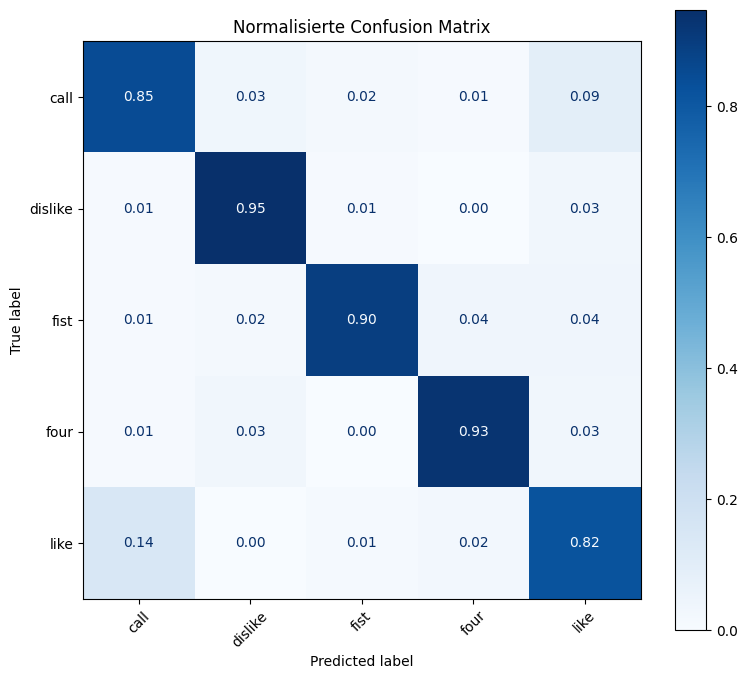

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay.from_predictions(
    all_true,
    all_predictions,
    labels=range(len(class_names)),
    display_labels=class_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Normalisierte Confusion Matrix")
plt.tight_layout()
plt.show()

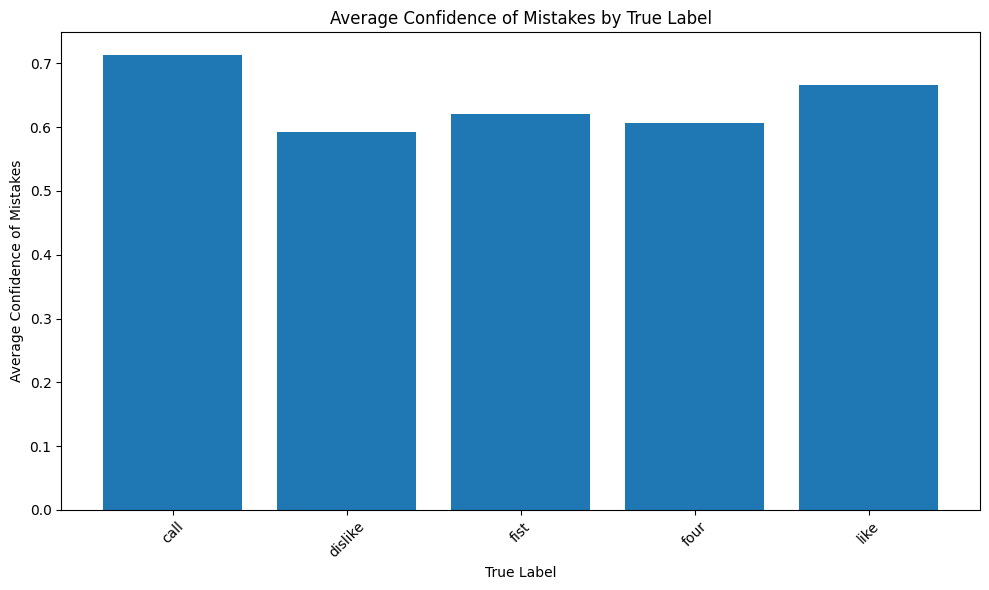

In [8]:
results = pd.DataFrame({
    "file_path": X,
    "true_id": all_true,
    "predicted_id": all_predictions,
    "confidence": all_confidences
})

results["true_label"] = results["true_id"].map(
    dict(enumerate(class_names))
)
results["predicted_label"] = results["predicted_id"].map(
    dict(enumerate(class_names))
)
results["correct"] = results["true_id"] == results["predicted_id"]

mistakes = results[~results["correct"]].sort_values(
    "confidence",
    ascending=False
)

mistakes_grouped=mistakes.groupby("true_label")["confidence"].mean().reset_index()

plt.figure(figsize=(10, 6))
plt.bar(
    mistakes_grouped["true_label"],
    mistakes_grouped["confidence"]
)
plt.xlabel("True Label")
plt.ylabel("Average Confidence of Mistakes")
plt.title("Average Confidence of Mistakes by True Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()




In [9]:
data = pd.read_csv("Data/data.csv")

data=data[["id","leading_hand", "age","gender","race"]]
results["id"]=results["file_path"].str.split("/").str[-1]
results["id"]=results["id"].str.replace(".jpg", "")

results=pd.merge(results, data, on="id", how="left")

results

,file_path,true_id,predicted_id,confidence,true_label,predicted_label,correct,id,leading_hand,age,gender,race
0,hagrid-sample-30k-384p/hagrid_30k/train_val_di...,1,1,0.980305,dislike,dislike,True,4818fb17-cb3b-4dce-b882-03e43fcec989,left,23.12,female,White
1,hagrid-sample-30k-384p/hagrid_30k/train_val_fi...,2,2,0.929837,fist,fist,True,56ed266f-e822-4a9b-8d5c-61d32d666740,left,42.97,female,White
2,hagrid-sample-30k-384p/hagrid_30k/train_val_fi...,2,2,0.967574,fist,fist,True,6128d3c2-9815-4eac-a2eb-696677ebf7e9,left,36.51,female,White
3,hagrid-sample-30k-384p/hagrid_30k/train_val_di...,1,1,0.950934,dislike,dislike,True,07a80421-7b0d-4d0f-96f1-37c22a1959f1,left,38.15,male,White
4,hagrid-sample-30k-384p/hagrid_30k/train_val_ca...,0,0,0.991271,call,call,True,6674a098-ccb2-46e6-aa20-59eb639a4aa3,left,38.00,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
495,hagrid-sample-30k-384p/hagrid_30k/train_val_fo...,3,3,0.994198,four,four,True,829d0838-4b80-4d9b-9e8a-c17148b97d16,left,24.70,female,White
496,hagrid-sample-30k-384p/hagrid_30k/train_val_ca...,0,0,0.795786,call,call,True,4e9cc64c-c2e5-4c88-97cd-e8fe92960fee,right,41.38,male,White
497,hagrid-sample-30k-384p/hagrid_30k/train_val_ca...,0,0,0.929661,call,call,True,35304810-a878-43de-899d-d532a16db2f3,right,26.63,female,White
498,hagrid-sample-30k-384p/hagrid_30k/train_val_di...,1,1,0.985661,dislike,dislike,True,57d15c2c-1ef5-48da-95a9-5195df6f78db,left,28.52,female,White
